# 08 · Обучаемая поправка к линейной интерполяции

**Вопрос:** уменьшает ли простая обучаемая модель ошибку восстановления скрытых наблюдений на других рейсах?

Продолжаем эксперимент 07 на тех же пригодных окнах 20–120 секунд. Линейная интерполяция дает исходную позицию, модель предсказывает поправку к востоку и северу в метрах. Используем регуляризованную линейную регрессию Ridge, реализованную через NumPy. Это первый воспроизводимый ориентир, без установки дополнительных библиотек.

**Протокол:** 6 рейсов train, 2 validation, 2 предварительный test. Все окна одного рейса находятся в одной части. Подбор регуляризации выполняется по средней ошибке validation с одинаковым весом рейсов. Test открывается после фиксации модели. Пилот уже просмотрен на этапе 07, поэтому это не независимое итоговое доказательство. Случай 43 км этим экспериментом не исправляется.

In [1]:
# Подключаем библиотеки и общие геодезические функции
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
sys.path.insert(0,str(root/'europe/scripts'))
from audit_c40_radial_cases import ellipsoid_distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
source_path = study/'data/public_pilot/EPWA_control_geometry.csv'
errors_path = study/'data/public_pilot/07_hidden_point_errors.csv'
source = pd.read_csv(source_path)
baseline_errors = pd.read_csv(errors_path)
audit07 = json.loads((study/'reports/07_hidden_point_audit.json').read_text(encoding='utf8'))
assert hashlib.sha256(source_path.read_bytes()).hexdigest() == audit07['source_sha256']
# Фиксируем детерминированный порядок рейсов до обучения
flights = sorted(source.case_flight_id.unique(), key=lambda f:hashlib.sha256(('08-v1:'+f).encode()).hexdigest())
assert len(flights) == 10
split = {f:part for part,subset in [('train',flights[:6]),('validation',flights[6:8]),('test',flights[8:])] for f in subset}
protocol = {'version':'08-v1','split':split,'alphas':[0.1,1.,10.,100.,1000.],
            'selection_metric':'validation macro mean WGS84 error, equal flight weights',
            'source_sha256':audit07['source_sha256'],
            'errors07_sha256':hashlib.sha256(errors_path.read_bytes()).hexdigest(),
            'test_status':'preliminary, pilot previously inspected',
            'refit_on_validation':False}
(study/'reports/08_ml_protocol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2)+'\n',encoding='utf8')
display(pd.DataFrame([{'Рейс':f,'Часть':part} for f,part in split.items()]))

,Рейс,Часть
0,EZY34MD_21230,train
1,EZY89BW_37984,train
2,EXS4112_71377,train
3,EZY1942_18429,train
4,EXS92K_22219,train
5,ENT73JH_21100,train
6,RYR4117_60025,validation
7,RYR67GT_63261,validation
8,RYR9BN_63693,test
9,RYR72ZC_66456,test


## 1. Формируем признаки и проверочные ответы

Каждая строка – задача восстановить одну скрытую точку по двум доступным концам. Время цели известно; ее координаты используются только как ответ. Признаки: длина интервала, доля времени, скорости, направления через sin/cos, возраст позиций на концах, смещение между концами и кинематические оценки поправки.

Все пространственные признаки выражены относительно концов, без идентификатора рейса и абсолютных координат. Для вычисления поправок используем локальное приближение в метрах; итоговую ошибку измеряем геодезически на WGS84. Погрешность самого наблюдения OpenSky неизвестна.

In [2]:
# Берем точно те же цели, которые сравнивались в эксперименте 07
key = ['flight_id','gap_s','left_time','target_time']
tasks = baseline_errors[baseline_errors.method.eq('linear_lat_lon')][key].copy()
assert not tasks.duplicated(key).any()
observed = source.rename(columns={'case_flight_id':'flight_id'})
assert not observed.duplicated(['flight_id','time']).any()
tasks['right_time'] = tasks.left_time+tasks.gap_s
# Присоединяем доступные концы отдельно от скрытого ответа
for role,time_col in [('a','left_time'),('b','right_time'),('target','target_time')]:
    fields = ['flight_id','time','lat','lon']
    if role != 'target':
        fields += ['velocity','heading','lastposupdate']
    renamed = observed[fields].rename(columns={c:f'{role}_{c}' for c in fields if c != 'flight_id'})
    tasks = tasks.merge(renamed,left_on=['flight_id',time_col],right_on=['flight_id',f'{role}_time'],validate='many_to_one')
tasks['part'] = tasks.flight_id.map(split)
w = (tasks.target_time-tasks.left_time)/tasks.gap_s
duration = tasks.gap_s
# Линейная интерполяция определяется только доступными концами
lon_delta = (tasks.b_lon-tasks.a_lon+180)%360-180
linear_lat = tasks.a_lat+w*(tasks.b_lat-tasks.a_lat)
linear_lon = tasks.a_lon+w*lon_delta
east_scale = 111320*np.cos(np.radians((tasks.a_lat+tasks.b_lat)/2))
north_scale = 111200
east = lon_delta*east_scale
north = (tasks.b_lat-tasks.a_lat)*north_scale
ha,hb = np.radians(tasks.a_heading),np.radians(tasks.b_heading)
va_e,va_n = tasks.a_velocity*np.sin(ha),tasks.a_velocity*np.cos(ha)
vb_e,vb_n = tasks.b_velocity*np.sin(hb),tasks.b_velocity*np.cos(hb)
curve = w*(1-w)*duration
# Кинематические подсказки используют только скорость и направление концов
features = pd.DataFrame({'gap_s':duration,'fraction':w,'curve_time_s':curve,
    'speed_a':tasks.a_velocity,'speed_b':tasks.b_velocity,
    'heading_a_sin':np.sin(ha),'heading_a_cos':np.cos(ha),
    'heading_b_sin':np.sin(hb),'heading_b_cos':np.cos(hb),
    'age_a':tasks.a_time-tasks.a_lastposupdate,'age_b':tasks.b_time-tasks.b_lastposupdate,
    'east_span':east,'north_span':north,
    'forward_residual_e':va_e*w*duration-w*east,
    'forward_residual_n':va_n*w*duration-w*north,
    'backward_residual_e':(1-w)*east-vb_e*(1-w)*duration,
    'backward_residual_n':(1-w)*north-vb_n*(1-w)*duration,
    'velocity_change_e':(vb_e-va_e)*curve,'velocity_change_n':(vb_n-va_n)*curve})
# Координаты скрытых точек появляются только в целевой поправке
target = np.column_stack([((tasks.target_lon-linear_lon+180)%360-180)*east_scale,
                          (tasks.target_lat-linear_lat)*north_scale])
usable = np.isfinite(features).all(axis=1) & np.isfinite(target).all(axis=1)
display(tasks.assign(usable=usable).groupby('part').agg(total=('flight_id','size'),usable=('usable','sum')))
# Сравниваем все методы на общей подвыборке при наличии пропусков признаков
tasks = tasks.loc[usable].reset_index(drop=True)
features = features.loc[usable].reset_index(drop=True)
target = target[usable]
linear_lat = linear_lat.loc[usable].to_numpy()
linear_lon = linear_lon.loc[usable].to_numpy()
east_scale = east_scale.loc[usable].to_numpy()
assert set(tasks.flight_id) == set(split)
display(features.head().round(3))
display(tasks.groupby(['part','flight_id']).size().rename('Число задач'))

,total,usable
part,,
test,3689,3689
train,11277,11277
validation,3935,3935


,gap_s,fraction,curve_time_s,speed_a,speed_b,heading_a_sin,heading_a_cos,heading_b_sin,heading_b_cos,age_a,age_b,east_span,north_span,forward_residual_e,forward_residual_n,backward_residual_e,backward_residual_n,velocity_change_e,velocity_change_n
0,20,0.5,5.0,208.493,207.998,0.999,-0.037,0.999,-0.040,0.218,0.007,4212.726,-163.063,-22.865,4.365,28.009,0.779,-2.572,-2.572
1,20,0.5,5.0,208.512,207.998,0.999,-0.039,0.999,-0.040,0.155,0.068,4170.851,-161.683,-1.927,-1.470,7.072,1.470,-2.572,0.000
2,20,0.5,5.0,207.998,207.998,0.999,-0.040,0.999,-0.040,0.007,0.009,4143.005,-162.891,6.851,-0.866,-6.851,0.866,0.000,0.000
3,20,0.5,5.0,207.998,207.998,0.999,-0.040,0.999,-0.040,0.068,0.175,4143.073,-162.891,6.817,-0.866,-6.817,0.866,0.000,0.000
4,20,0.5,5.0,207.998,208.019,0.999,-0.040,0.999,-0.042,0.009,0.194,4084.477,-165.824,36.115,0.601,-36.115,4.543,0.000,-2.572


part        flight_id    
test        RYR72ZC_66456    2110
            RYR9BN_63693     1579
train       ENT73JH_21100    1731
            EXS4112_71377    2054
            EXS92K_22219     1504
            EZY1942_18429    1977
            EZY34MD_21230    1882
            EZY89BW_37984    2129
validation  RYR4117_60025    1958
            RYR67GT_63261    1977
Name: Число задач, dtype: int64

## 2. Обучаем регрессию и выбираем регуляризацию

Стандартизация признаков вычисляется только на train. Ridge минимизирует квадрат ошибки двух поправок и штрафует крупные коэффициенты. Свободный член не штрафуется. Подбираем α из заранее заданного списка на validation.

Перекрывающиеся окна не независимы. При обучении каждому рейсу даем одинаковый суммарный вес; задачи внутри рейса имеют одинаковый вес. Сетка регуляризации не пересматривается после просмотра test.

In [3]:
train_mask = tasks.part.eq('train').to_numpy()
val_mask = tasks.part.eq('validation').to_numpy()
test_mask = tasks.part.eq('test').to_numpy()
assert not (train_mask & val_mask).any() and not (train_mask & test_mask).any()
# Оцениваем параметры преобразования только на обучающих рейсах
mean = features.loc[train_mask].mean().to_numpy()
scale = features.loc[train_mask].std(ddof=0).to_numpy(copy=True)
scale[scale < 1e-12] = 1
x = np.column_stack([np.ones(len(features)),(features.to_numpy()-mean)/scale])
counts = tasks.loc[train_mask].groupby('flight_id').size()
weights = tasks.loc[train_mask,'flight_id'].map(1/counts).to_numpy(copy=True)
weights *= len(weights)/weights.sum()
# Решаем взвешенную задачу Ridge сразу для востока и севера
def fit_ridge(alpha):
    a = x[train_mask]
    penalty = np.eye(a.shape[1])*alpha
    penalty[0,0] = 0
    return np.linalg.solve(a.T@(weights[:,None]*a)+penalty,
                           a.T@(weights[:,None]*target[train_mask]))

def prediction_error(mask, correction):
    lat = linear_lat[mask]+correction[:,1]/north_scale
    lon = linear_lon[mask]+correction[:,0]/east_scale[mask]
    return 1000*ellipsoid_distance(tasks.loc[mask,'target_lat'].to_numpy(),
                                   tasks.loc[mask,'target_lon'].to_numpy(),lat,lon)

def macro_mean(mask, error):
    return pd.DataFrame({'flight_id':tasks.loc[mask,'flight_id'].to_numpy(),'error':error}).groupby('flight_id').error.mean().mean()

selection = []
for alpha in protocol['alphas']:
    coef = fit_ridge(alpha)
    error = prediction_error(val_mask,x[val_mask]@coef)
    selection.append({'alpha':alpha,'validation_macro_mean_m':macro_mean(val_mask,error)})
selection = pd.DataFrame(selection).sort_values(['validation_macro_mean_m','alpha'])
best_alpha = float(selection.iloc[0].alpha)
coef = fit_ridge(best_alpha)
display(selection.round(3))
# Сохраняем выбранную модель до расчета результатов test
np.savez(study/'data/public_pilot/08_ridge_model.npz',coef=coef,mean=mean,scale=scale,
         feature_names=features.columns.to_numpy(dtype=str),alpha=best_alpha)
selection.to_csv(study/'reports/08_validation_selection.csv',index=False)
display(Markdown(f'**Зафиксирована регуляризация α = {best_alpha:g}**'))

,alpha,validation_macro_mean_m
3,100.0,136.023
2,10.0,137.095
1,1.0,137.338
0,0.1,137.365
4,1000.0,145.818


**Зафиксирована регуляризация α = 100**

## 3. Открываем предварительный test и сравниваем методы

Модель остается обученной только на train. Не переобучаем ее на validation после выбора. Оценка проводится на одинаковых скрытых целях для четырех методов. Train показан только для диагностики, а основной вопрос – результат на двух test-рейсах.

Сначала считаем показатели по каждому рейсу, затем усредняем рейсовые показатели с одинаковым весом. Среднее медиан и среднее P95 не являются медианой и P95 объединенных ошибок.

In [4]:
# Получаем предсказания зафиксированной модели без использования скрытого ответа
correction = x@coef
ml_errors = prediction_error(np.ones(len(tasks),dtype=bool),correction)
assert np.isfinite(ml_errors).all()
evaluation = baseline_errors.merge(tasks[key+['part']],on=key,how='inner',validate='many_to_one')
ml = tasks[key+['part']].copy()
ml['method'] = 'ridge_correction'
ml['error_m'] = ml_errors
evaluation = pd.concat([evaluation,ml],ignore_index=True)
assert evaluation.groupby(key).method.nunique().eq(4).all()
# Убеждаемся, что линейный ориентир воспроизведен с той же геодезической ошибкой
linear_errors = prediction_error(np.ones(len(tasks),dtype=bool),np.zeros((len(tasks),2)))
saved_linear = evaluation[evaluation.method.eq('linear_lat_lon')].set_index(key).error_m
assert np.allclose(saved_linear.reindex(pd.MultiIndex.from_frame(tasks[key])),linear_errors,atol=1e-5)
per_flight = evaluation.groupby(['part','flight_id','method']).error_m.agg(
    targets='size',mean_m='mean',median_m='median',p95_m=lambda s:s.quantile(.95),max_m='max').reset_index()
macro = per_flight.groupby(['part','method'])[['mean_m','median_m','p95_m']].mean()
display(macro.round(2))
display(per_flight[per_flight.part.eq('test')].round(2))
per_flight.to_csv(study/'reports/08_ml_by_flight.csv',index=False)
macro.to_csv(study/'reports/08_ml_macro.csv')
evaluation.to_csv(study/'data/public_pilot/08_ml_errors.csv',index=False)

mean_m  median_m    p95_m
part       method                                              
test       constant_velocity_sphere   638.48    139.86  3168.61
           linear_lat_lon             316.44    127.68  1257.21
           nearest                   3752.71   2819.49  9558.40
           ridge_correction           124.57     62.60   478.95
train      constant_velocity_sphere   621.46    135.91  3168.30
           linear_lat_lon             332.65    121.00  1494.91
           nearest                   3505.97   2667.92  8869.99
           ridge_correction           124.41     56.24   515.43
validation constant_velocity_sphere   636.06    113.07  3484.06
           linear_lat_lon             337.46    105.23  1680.95
           nearest                   3369.20   2760.39  8215.17
           ridge_correction           136.02     54.60   575.84

,part,flight_id,method,targets,mean_m,median_m,p95_m,max_m
0,test,RYR72ZC_66456,constant_velocity_sphere,2110,734.69,105.29,4156.23,12083.73
1,test,RYR72ZC_66456,linear_lat_lon,2110,393.84,99.90,1806.17,3268.97
2,test,RYR72ZC_66456,nearest,2110,3635.93,2867.05,8979.67,11646.64
3,test,RYR72ZC_66456,ridge_correction,2110,161.83,68.96,676.35,1722.27
4,test,RYR9BN_63693,constant_velocity_sphere,1579,542.27,174.43,2180.99,10633.82
5,test,RYR9BN_63693,linear_lat_lon,1579,239.05,155.47,708.25,2056.30
6,test,RYR9BN_63693,nearest,1579,3869.50,2771.93,10137.14,13343.51
7,test,RYR9BN_63693,ridge_correction,1579,87.31,56.23,281.54,631.08


## 4. Результат на новых для обучения рейсах

Зеленый показывает линейный ориентир, красный – обучаемую поправку. Если красный столбец выше, модель ухудшает результат. График длины интервала использует одинаковый вес test-рейсов; никакой настройки модели по этому графику не выполняется.

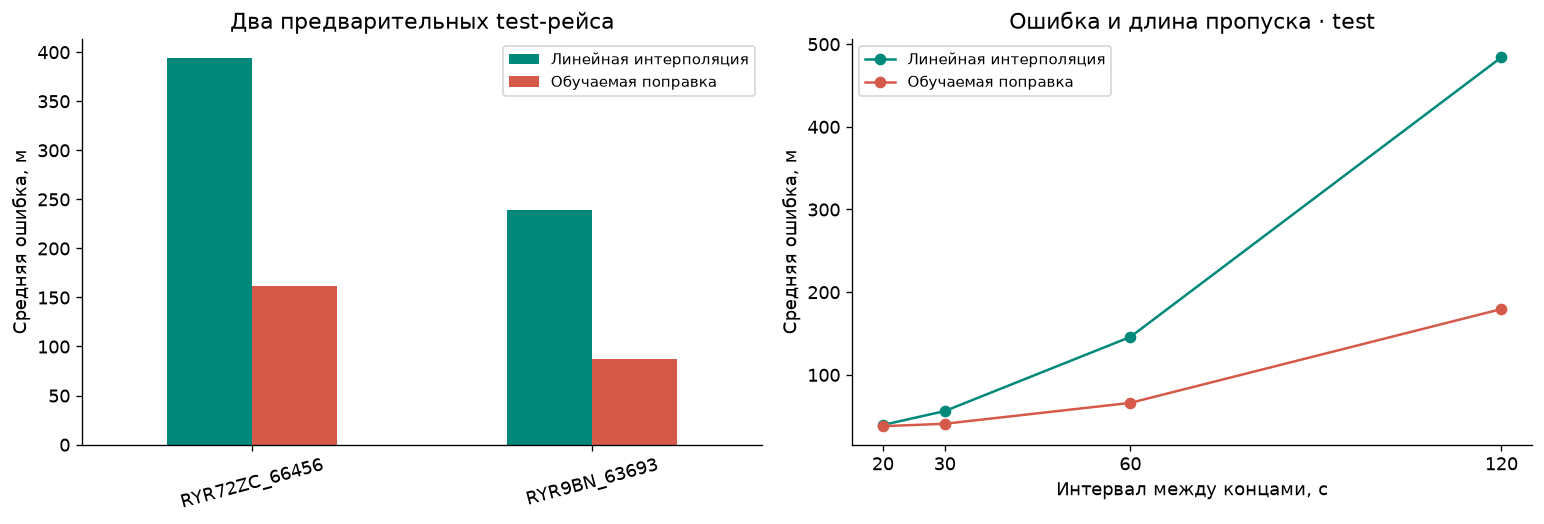

**Средняя рейсовая ошибка test:** линейный метод 316.4 м, модель 124.6 м. Изменение в пользу модели: **+60.6%**.

1036

In [5]:
labels = {'linear_lat_lon':'Линейная интерполяция','ridge_correction':'Обучаемая поправка'}
colors = {'linear_lat_lon':'#00897B','ridge_correction':'#D65A4A'}
test = evaluation[evaluation.part.eq('test')]
fig, axes = plt.subplots(1,2,figsize=(13,4.5))
# Сравниваем средние ошибки отдельно на каждом проверочном рейсе
flight_plot = per_flight[(per_flight.part == 'test') & per_flight.method.isin(labels)]
table = flight_plot.pivot(index='flight_id',columns='method',values='mean_m')
table.rename(columns=labels).plot.bar(ax=axes[0],color=[colors[m] for m in table.columns])
axes[0].set(title='Два предварительных test-рейса',ylabel='Средняя ошибка, м',xlabel='')
axes[0].tick_params(axis='x',rotation=15)
axes[0].legend(fontsize=9)
# Сначала агрегируем по рейсу и интервалу, затем по интервалу
by_gap = test.groupby(['flight_id','gap_s','method']).error_m.mean().reset_index()
gap_macro = by_gap.groupby(['gap_s','method']).error_m.mean().reset_index()
for method in labels:
    group = gap_macro[gap_macro.method.eq(method)]
    axes[1].plot(group.gap_s,group.error_m,'o-',color=colors[method],label=labels[method])
axes[1].set(title='Ошибка и длина пропуска · test',xlabel='Интервал между концами, с',ylabel='Средняя ошибка, м',xticks=[20,30,60,120])
axes[1].legend(fontsize=9)
plt.tight_layout()
fig.savefig(study/'figures/08_ml_correction.png',dpi=180)
plt.show()
gap_macro.to_csv(study/'reports/08_ml_test_by_gap.csv',index=False)
# Формулируем вывод из фактических результатов, независимо от знака улучшения
baseline = float(macro.loc[('test','linear_lat_lon'),'mean_m'])
learned = float(macro.loc[('test','ridge_correction'),'mean_m'])
improvement = 100*(baseline-learned)/baseline
display(Markdown(f'**Средняя рейсовая ошибка test:** линейный метод {baseline:.1f} м, '
                 f'модель {learned:.1f} м. Изменение в пользу модели: **{improvement:+.1f}%**.'))
result = {'alpha':best_alpha,'split':split,'features':list(features.columns),
          'eligible_tasks':len(tasks),'test_linear_macro_mean_m':baseline,
          'test_model_macro_mean_m':learned,'improvement_percent':improvement,
          'source_sha256':protocol['source_sha256'],'independent_final_test':False}
(study/'reports/08_ml_audit.json').write_text(json.dumps(result,ensure_ascii=False,indent=2)+'\n',encoding='utf8')

## Выводы и ограничения

Мы обучили одну простую модель, выбрали регуляризацию на validation и проверили зафиксированный вариант на других рейсах. Знак улучшения указан выше; отрицательный результат также является результатом эксперимента.

Два рейса не дают надежной оценки переносимости. Все данные относятся к одному ранее просмотренному пилоту; перекрывающиеся окна не независимы. Модель не получает скрытые позиции в признаках, но ее ответы основаны на наблюдениях OpenSky, не на независимом истинном положении. Локальное представление поправки ограничено областью этого пилота.

Следующий шаг – разобрать ошибки по направлениям и поворотам, затем зафиксировать протокол и собрать отдельные рейсы других дат. Любое изменение модели после просмотра этого test делает его частью разработки. Не утверждаем, что расхождение 43 км устранено.